**Question 1**

(a)

i.

Because Y is natural number, which can be considered as counting number. Poisson distribution is starting for nonnegative count outcomes. Then, Poisson distribution is a reasonable choice for Y.

ii.

Because for Poisson distribution, the parameters should be positive. exp() link function can make parameters at any value into positive.

(b)

Since the probability function of Poisson distribution is:

$$
P(Y \mid X) = \frac{e^{-\mu}\mu^Y}{Y!},
\qquad \mu = \exp(f(X)).
$$

the loss function should be the negative-log likelihood:

$$
L(f(x), Y)
= -\log P(Y \mid X=x)
= \exp(f(x)) - Y f(x) + \log(Y!).
$$

(c)

$$
\frac{\partial L}{\partial f(x)}
= \exp(f(x)) - Y.
$$

(d)

First, we need to nitialize the model with the constant that minimizes the training loss: $f_0(x)=\log\bar y$ according to the equation in (c).

At iteration $m$, we compute the negative gradients: $r_{im} = -\left.\frac{\partial L(f(x_i),y_i)}{\partial f(x_i)}\right|_{f=f_{m-1}} = y_i-\exp(f_{m-1}(x_i))$.

Then, we choose a regression tree $h_m$ by fitting the pseudo-residuals using least squares: $h_m \in \arg\min_{h\in\mathcal{H}}
\sum_{i=1}^{n}\left(r_{im}-h(x_i)\right)^2$, where $\mathcal{H}$ is the class of allowed regression trees.

After that, we choose the step size $\lambda_m$ by minimizing the original loss
along the direction $h_m$: $\lambda_m \in \arg\min_{\lambda}\sum_{i=1}^{n}L\left(f_{m-1}(x_i)+\lambda h_m(x_i),y_i\right)$, or we can use constant learning rate.

Finally, we update the model by $f_m(x)=f_{m-1}(x)+\eta\lambda_m h_m(x)$ till convergence or the largest number of tree.

**Question 2**

(a)

According to Hoeffding inequality, the inequation for each model $h_j$ should be:

$$
P\left(
\left|\widehat{R}_{\mathrm{test}}(h_j)-R(h_j)\right|>\varepsilon
\right)
\le 2\exp\left(-\frac{2l\varepsilon^2}{B^2}\right),
$$

where $\varepsilon$ is the bound of the difference between empirical risk and true risk, and the range of loss is $[0, B].$

In order to minimize gaps for all $k$ models, we need to apply the union bound over all of them:

$$
P\left(
\max_{j\leq k}\left|\widehat{R}_{\mathrm{test}}(h_j)-R(h_j)\right|>\varepsilon
\right)
\leq 2k\exp\left(-\frac{2l\varepsilon^2}{B^2}\right).
$$

Let $\delta\in(0,1)$ denote the desired failure probability, so the bound holds with probability at least $1-\delta$. Therefore:

$$
2k\exp\left(-\frac{2l\varepsilon^2}{B^2}\right)=\delta.
$$

$$
\varepsilon = B\sqrt{\frac{\ln(2k/\delta)}{2l}}.
$$

Finally, the formula of the bound is:

$$
\left|\widehat{R}_{\mathrm{test}}(h_j)-R(h_j)\right|
\le B\sqrt{\frac{\ln(2k/\delta)}{2l}}.
$$

(b)

Using the same test set to select hyperparameters can produce an optimistic estimate of generalization. The selected model will have a low test error partly because it is selected based on the test set. If k is large relative to l, there will be many hyperparameter configurations using relatively few test observations. This increases the chance of selecting a model with low test error rather than better generalization.

(c)

In [9]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display, Markdown
from sklearn.model_selection import train_test_split, ParameterGrid
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingClassifier
from sklearn.metrics import mean_squared_error, accuracy_score, log_loss
from joblib import Parallel, delayed

SEED = 42
DATA_DIR = Path('.')
plt.rcParams.update({'figure.figsize': (9, 4), 'axes.grid': True})
print('scikit-learn version:', sklearn.__version__)

scikit-learn version: 1.9.1


In [10]:
wine = pd.read_csv('winequality-white.csv', sep=';')

X_wine = wine.drop(columns='quality')
y_wine = wine['quality']
X_trainval, X_test, y_trainval, y_test = train_test_split(
    X_wine, y_wine, test_size=0.20, random_state=SEED)
X_train, X_val, y_train, y_val = train_test_split(
    X_trainval, y_trainval, test_size=0.125, random_state=SEED)

display(pd.DataFrame({'split': ['train', 'validation', 'test'],
                      'n': [len(y_train), len(y_val), len(y_test)]}))
print('Shape:', wine.shape, '| observed quality range:', (y_wine.min(), y_wine.max()))
print('Exact duplicate rows:', wine.duplicated().sum())

scaler = StandardScaler().fit(X_train)
X_train_s = scaler.transform(X_train)
X_val_s = scaler.transform(X_val)

knn_grid = list(ParameterGrid({'n_neighbors': list(range(1, 131)),
                             'weights': ['uniform', 'distance'], 'p': [1, 2]}))
rf_grid = list(ParameterGrid({'n_estimators': [10, 20, 40],
    'max_depth': [None, 4, 8, 12], 'min_samples_leaf': [1, 2, 3, 4, 6, 8, 12],
    'max_features': [0.4, 0.7, 1.0], 'bootstrap': [True, False]}))
print('KNN candidates:', len(knn_grid), '| RF candidates:', len(rf_grid))

,split,n
0,train,3428
1,validation,490
2,test,980


Shape: (4898, 12) | observed quality range: (np.int64(3), np.int64(9))
Exact duplicate rows: 937
KNN candidates: 520 | RF candidates: 504


In [11]:
def evaluate_candidate(model_name, params):
    if model_name == 'KNN':
        model = KNeighborsRegressor(**params, n_jobs=1)
        model.fit(X_train_s, y_train)
        pred = model.predict(X_val_s)
    else:
        model = RandomForestRegressor(**params, random_state=SEED, n_jobs=1)
        model.fit(X_train, y_train)
        pred = model.predict(X_val)
    return {'params': params, 'validation_MSE': mean_squared_error(y_val, pred)}

search_results = {}
best_params = {}
for name, grid in [('KNN', knn_grid), ('RF', rf_grid)]:
    rows = Parallel(n_jobs=2)(delayed(evaluate_candidate)(name, p) for p in grid)
    table = pd.DataFrame(rows).sort_values('validation_MSE', kind='stable').reset_index(drop=True)
    search_results[name] = table
    best_params[name] = table.loc[0, 'params']
    print(name, 'best parameters:', best_params[name])
    display(table.head(5))

KNN best parameters: {'n_neighbors': 25, 'p': 1, 'weights': 'distance'}


,params,validation_MSE
0,"{'n_neighbors': 25, 'p': 1, 'weights': 'distan...",0.298739
1,"{'n_neighbors': 19, 'p': 1, 'weights': 'distan...",0.299662
2,"{'n_neighbors': 18, 'p': 1, 'weights': 'distan...",0.299994
3,"{'n_neighbors': 28, 'p': 1, 'weights': 'distan...",0.300058
4,"{'n_neighbors': 17, 'p': 1, 'weights': 'distan...",0.300187


RF best parameters: {'bootstrap': False, 'max_depth': None, 'max_features': 0.4, 'min_samples_leaf': 2, 'n_estimators': 40}


,params,validation_MSE
0,"{'bootstrap': False, 'max_depth': None, 'max_f...",0.297968
1,"{'bootstrap': False, 'max_depth': None, 'max_f...",0.304602
2,"{'bootstrap': False, 'max_depth': None, 'max_f...",0.305354
3,"{'bootstrap': False, 'max_depth': None, 'max_f...",0.306102
4,"{'bootstrap': False, 'max_depth': None, 'max_f...",0.306255


,model,candidates,train_MSE,validation_MSE,test_MSE,test_minus_validation
0,KNN,520,0.000000,0.298739,0.368550,0.069811
1,RF,504,0.019148,0.297968,0.347257,0.049289


Mean-predictor test MSE: 0.7757230069544568


**KNN:** validation MSE = 0.2987; test MSE = 0.3686; test − validation = +0.0698.

**RF:** validation MSE = 0.2980; test MSE = 0.3473; test − validation = +0.0493.

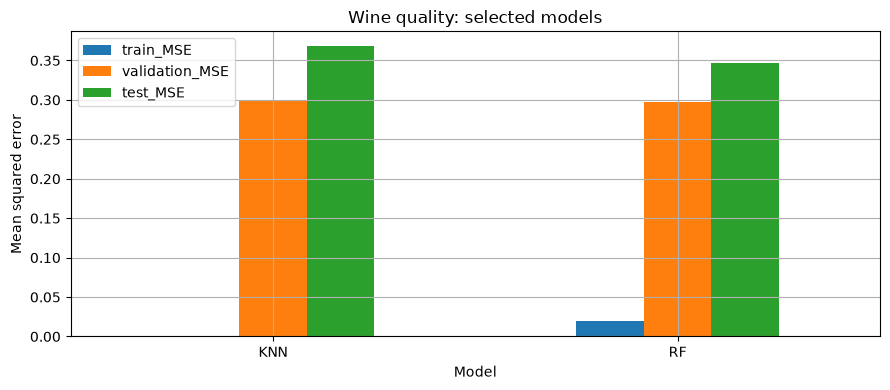

In [12]:
selected_models = {
    'KNN': KNeighborsRegressor(**best_params['KNN'], n_jobs=1).fit(X_train_s, y_train),
    'RF': RandomForestRegressor(**best_params['RF'], random_state=SEED, n_jobs=1).fit(X_train, y_train)
}
X_test_s = scaler.transform(X_test)
performance = []

for name, model in selected_models.items():
    a, b, c = (X_train_s, X_val_s, X_test_s) if name == 'KNN' else (X_train, X_val, X_test)
    tr = mean_squared_error(y_train, model.predict(a))
    va = mean_squared_error(y_val, model.predict(b))
    te = mean_squared_error(y_test, model.predict(c))
    performance.append({'model': name, 'candidates': len(search_results[name]),
        'train_MSE': tr, 'validation_MSE': va, 'test_MSE': te,
        'test_minus_validation': te-va})
performance = pd.DataFrame(performance)
display(performance.round(6))
print('Mean-predictor test MSE:', mean_squared_error(y_test, np.full(len(y_test), y_train.mean())))

for row in performance.itertuples():
    display(Markdown(f"**{row.model}:** validation MSE = {row.validation_MSE:.4f}; "
        f"test MSE = {row.test_MSE:.4f}; test − validation = {row.test_minus_validation:+.4f}."))
fig, ax = plt.subplots()
performance.set_index('model')[['train_MSE', 'validation_MSE', 'test_MSE']].plot.bar(ax=ax)
ax.set(ylabel='Mean squared error', title='Wine quality: selected models', xlabel='Model')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

For KNN, the selected configuration used 25 neighbors, Manhattan distance, and inverse-distance weighting. The validation and test MSE were 0.298739 and 0.368550. For the random forest, the selected configuration used 40 trees, unlimited depth, a minimum leaf size of 2, a feature fraction of 0.4, and no bootstrapping. The validation and test MSE were 0.297968 and 0.347257. Both validation errors were lower than their corresponding test errors. The untouched test set should provide an independent estimate of generalization performance.

**Question 3**

(a)

In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score, log_loss

TREE_COUNTS = [1, 10, 100, 300, 1000]


def evaluate_boosting(filename):
    data = pd.read_csv(filename, header=None)
    X = data.iloc[:, 1:]
    y = data.iloc[:, 0].astype(int)

    X_train, X_test, y_train, y_test = train_test_split(
        X, y,
        test_size=0.30,
        random_state=42,
        stratify=y
    )

    results = []

    for n_trees in TREE_COUNTS:
        model = GradientBoostingClassifier(
            n_estimators=n_trees,
            learning_rate=0.1,
            max_depth=1,
            random_state=42
        )
        model.fit(X_train, y_train)

        train_pred = model.predict(X_train)
        test_pred = model.predict(X_test)

        train_prob = model.predict_proba(X_train)
        test_prob = model.predict_proba(X_test)

        results.append({
            "trees": n_trees,
            "train_error": 1 - accuracy_score(y_train, train_pred),
            "test_error": 1 - accuracy_score(y_test, test_pred),
            "train_logloss": log_loss(y_train, train_prob),
            "test_logloss": log_loss(y_test, test_prob)
        })

    return pd.DataFrame(results)


def plot_results(results, title):
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))

    axes[0].plot(
        results["trees"], results["train_error"],
        "o-", label="Train"
    )
    axes[0].plot(
        results["trees"], results["test_error"],
        "o-", label="Test"
    )
    axes[0].set_ylabel("Classification error")

    axes[1].plot(
        results["trees"], results["train_logloss"],
        "o-", label="Train"
    )
    axes[1].plot(
        results["trees"], results["test_logloss"],
        "o-", label="Test"
    )
    axes[1].set_ylabel("Log loss")

    for ax in axes:
        ax.set_xscale("log")
        ax.set_xlabel("Number of trees")
        ax.legend()
        ax.grid(alpha=0.3)

    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

,trees,train_error,test_error,train_logloss,test_logloss
0,1,0.4257,0.4267,0.6769,0.6749
1,10,0.3857,0.4133,0.6470,0.6452
2,100,0.1743,0.2267,0.4990,0.5278
3,300,0.1057,0.2200,0.3779,0.4969
4,1000,0.0686,0.2133,0.2543,0.5657


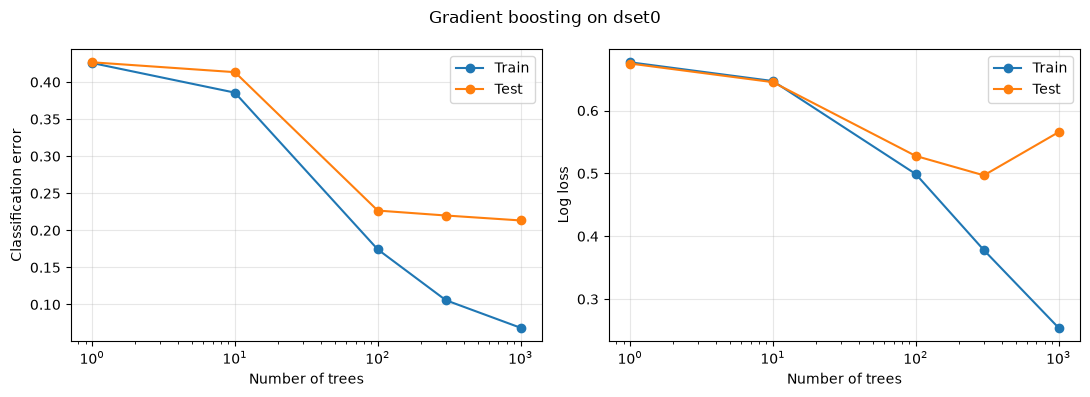

In [14]:
results0 = evaluate_boosting("dset0.csv")

display(results0.round(4))
plot_results(results0, "Gradient boosting on dset0")

In dset0, held-out classification error decreased as trees were added. However, held-out log loss increased from 0.4969 at 300 trees to 0.5657 at 1,000 trees while training log loss was decreasing. Thus, additional boosting stages showed overfitting.

(b)

,trees,train_error,test_error,train_logloss,test_logloss
0,1,0.4543,0.4533,0.6546,0.6673
1,10,0.1971,0.3067,0.5151,0.5814
2,100,0.1086,0.2333,0.3107,0.4020
3,300,0.0714,0.1800,0.2313,0.3576
4,1000,0.0457,0.1933,0.1621,0.3896


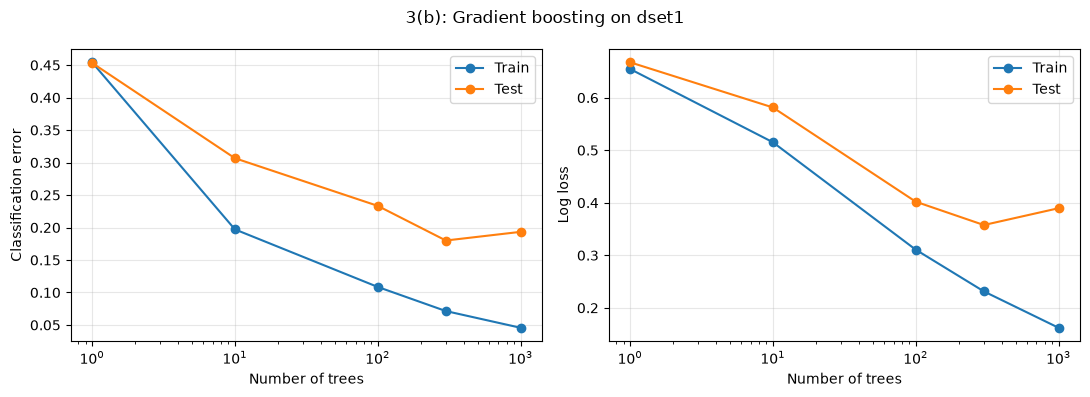

In [15]:
results1 = evaluate_boosting("dset1.csv")

display(results1.round(4))
plot_results(results1, "3(b): Gradient boosting on dset1")

In dset1, held-out error decreased to 0.1800 at 300 trees and rose to 0.1933 at 1,000 trees. Held-out log loss also rose from 0.3576 to 0.3896 in that interval, despite the improvement in training loss. This also showed overfitting from 300 to 1000 trees.

(c)

,trees,dset0_test_error,dset1_test_error,dset0_test_logloss,dset1_test_logloss
0,1,0.4267,0.4533,0.6749,0.6673
1,10,0.4133,0.3067,0.6452,0.5814
2,100,0.2267,0.2333,0.5278,0.4020
3,300,0.2200,0.1800,0.4969,0.3576
4,1000,0.2133,0.1933,0.5657,0.3896


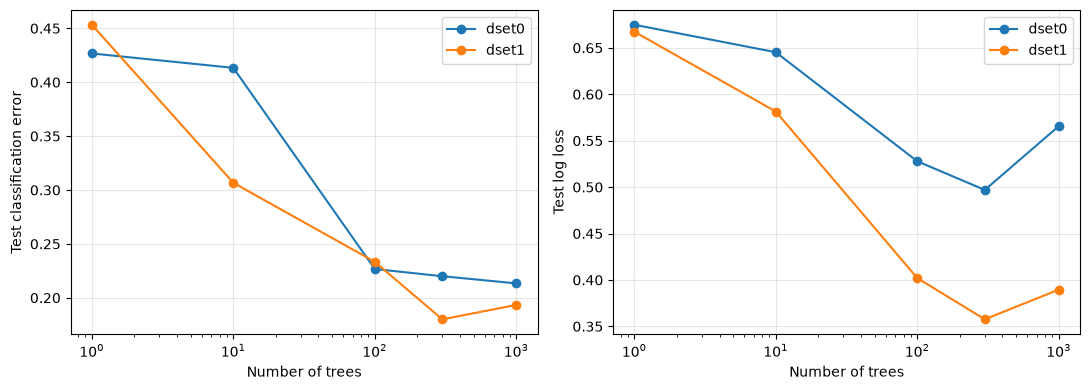

In [16]:
comparison = pd.DataFrame({
    "trees": TREE_COUNTS,
    "dset0_test_error": results0["test_error"],
    "dset1_test_error": results1["test_error"],
    "dset0_test_logloss": results0["test_logloss"],
    "dset1_test_logloss": results1["test_logloss"]
})

display(comparison.round(4))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for name, results in [("dset0", results0), ("dset1", results1)]:
    axes[0].plot(
        results["trees"], results["test_error"],
        "o-", label=name
    )
    axes[1].plot(
        results["trees"], results["test_logloss"],
        "o-", label=name
    )

axes[0].set_ylabel("Test classification error")
axes[1].set_ylabel("Test log loss")

for ax in axes:
    ax.set_xscale("log")
    ax.set_xlabel("Number of trees")
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

The models on dset1 learned faster and achieved lower test error and log loss than those on dset0 at 300 trees. Beyond 300 trees, dset1 showed an increase in both test classification error and test log loss. In contrast, dset0's test classification error continued to decrease, while its test log loss increased more substantially. These differences may reflect the differences in signal strength, class overlap or noise. Noisy or overlapping observations can cause boosting stages to fit sample-specific patterns rather than generalization.